# Multicamera volumetric particle trajectories


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：multicamera_volumetric_particle_trajectories

**观测 y：** observations(1, 100, 4, 1024, 1024)；camera_matrix(1, 4, 3, 3)；rotation(1, 4, 3, 3)；inverse_rotation(1, 4, 3, 3)；translation(1, 4, 3)；camera_centres(1, 4, 3)；distortion(1, 4, 5)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 100帧三维粒子位置和轨迹ID。

**GT/参考来源：** GT为生成观测之前定义的模拟物理目标；须与无噪声观测/拟合预测区分。

**由观测恢复目标：** 带畸变透视投影产生Gaussian粒子强度。本地路径为 `solvers.reconstruct→numeric_tracking本地C++核`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 3, 5, 6, 8, 9, 13, 14, 15, 16, 17, 19, 20, 21, 22, 23（cell编号按文件内从0计）。章节包括：# Multicamera volumetric particle trajectories；## 2. Data: complete native sequence and legitimate geometry；## 3. Physics: cameras, rays and projected intensity；## 4. Method: exclusive correspondences, refinement and trajectory prediction；Initial trajectories use a51³node particle-space displacement field. At each node, local pair displacements form a Gaussian-smoothed histogram; sub-bin log-Gaussian peaks and spatial smoothing provide initialization. Established tracks use adaptive LMS prediction from their last at most six positions, image-domain refinement, residual IPR and conflict-resolved association. Linear last-point consistency prunes erratic tracks. Full details, units, exact stopping and boundary arithmetic are in both plans.；## 5. Results: spatial accuracy and temporal completeness；The paper compares raw and smoothed tracks and warns that a smoothed reconstruction is not independent truth. Here genuine simulated truth permits a direct comparison. Gaussian smoothing below is a labelled diagnostic, applied per returned segment with nearest endpoint continuation. It never changes the submitted reconstruction or its acceptance criteria.；## 6. Conclusion and limits。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 1250000位置manifest是生成器真值；完整400幅图像参与本地求解。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem: depth, overlap and temporal identity

We recover complete three-dimensional positions and time-connected particle segments from four synchronized camera sequences. These are **author-existing simulated observations**, not a real experiment or a new maintainer simulation. The independent author manifest supplies actual simulated truth. The selected modern tracer method, its unchanged original run, the minimally qualified source run, and fresh local results are separately identified.

A camera observes a depth-collapsed projection. Dense peaks create false geometrical intersections; accurate isolated points still do not establish correct trajectories. We therefore examine position error, coverage, precision, fragmentation and temporal connections together. This notebook actively reconstructs all100frames and400native images. No cached reconstruction substitutes for the fresh path.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,os,time,json,hashlib,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.collections import LineCollection
from scipy.spatial import cKDTree
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,camera_parameters
from src.solvers import reconstruct
from src.physics_model import project,rays,detect,estimate_otf,refine,residual,reconstruct_frame,stereo_diagnostics,triangulate_candidates
from src.generate_data import known_particle_images
from src.visualization import segment_velocity,gaussian_smooth_tracks
spec=importlib.util.spec_from_file_location('local_independent_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'savefig.bbox':'tight'})
FIGURE_DIR=Path('D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research_batch8_20261022\\groups\\astro_earth_mech\\openlpt\\figures');FIGURE_DIR.mkdir(parents=True,exist_ok=True);figure_index=[]
def export(fig,number,title,**numeric):
    stem=f'figure_{number:02d}';np.savez_compressed(FIGURE_DIR/(stem+'.npz'),**numeric)
    files={}
    for extension in ['png','svg','pdf']:
        path=FIGURE_DIR/(stem+'.'+extension);fig.savefig(path,dpi=160);files[extension]={'path':str(path),'sha256':hashlib.sha256(path.read_bytes()).hexdigest()}
    files['numeric']={'path':str(FIGURE_DIR/(stem+'.npz')),'sha256':hashlib.sha256((FIGURE_DIR/(stem+'.npz')).read_bytes()).hexdigest()}
    record={'number':number,'title':title,'files':files,'numeric_keys':list(numeric)};figure_index.append(record);(FIGURE_DIR/(stem+'.json')).write_text(json.dumps(record,indent=2),encoding='utf8');plt.show();plt.close(fig)
def point_case(points,frame=0):
    q=truth[0][truth[1]==frame];distance,nn=cKDTree(q).query(points);order=np.argsort(distance,kind='stable');used=set();keep=[]
    for i in order:
        if distance[i]>.1:break
        if int(nn[i]) in used:continue
        used.add(int(nn[i]));keep.append(i)
    keep=np.asarray(keep,int);return np.array([len(keep)/len(q),len(keep)/len(points) if len(points)else 0,float(np.sqrt(np.mean(distance[keep]**2)))if len(keep)else .1])
data=load_data(ROOT/'data/raw_data.npz');cal=camera_parameters(data)
truth=judge.read_tracks(ROOT/'evaluation/ground_truth.npz',truth=True)
print('Kernel:',sys.executable,'observations:',data['observations'].shape,'truth points:',len(truth[0]))

Kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe observations: (1, 100, 4, 1024, 1024) truth points: 1250000


## 2. Data: complete native sequence and legitimate geometry

All four1024×1024 views and100frames are retained. Camera matrices have a negative vertical focal sign; their rounded rotations have supplied algebraic inverses. Camera origins and all distortion coefficients are legitimate input. Gaussian widths are estimated afresh from the first five native images per camera, never loaded from a hidden reconstructed target.

The40mm cube uses XYZ millimetres. The author's runtime convention is one second per frame; derived velocities use that convention and do not claim an independently measured experimental sampling frequency. No paper table value is reused as a fresh measurement.

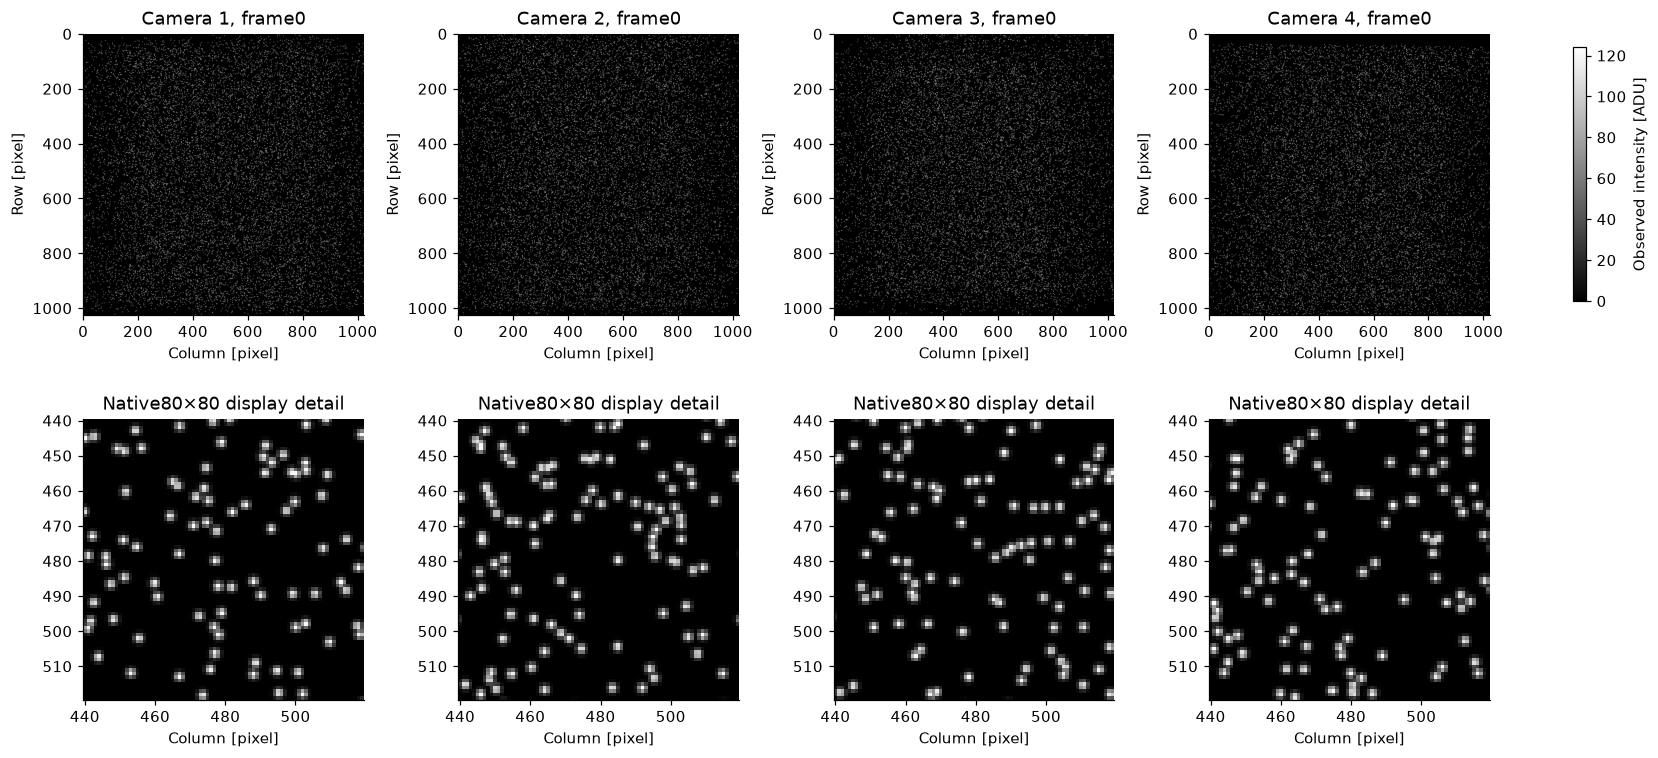

In [2]:
fig,axes=plt.subplots(2,4,figsize=(15,7),layout='constrained')
for c in range(4):
    image=data['observations'][0,0,c];im=axes[0,c].imshow(image,cmap='gray',vmin=0,vmax=124);axes[0,c].set_title(f'Camera {c+1}, frame0');axes[0,c].set_xlabel('Column [pixel]');axes[0,c].set_ylabel('Row [pixel]')
    axes[1,c].imshow(image[440:520,440:520],cmap='gray',vmin=0,vmax=124,extent=[439.5,519.5,519.5,439.5]);axes[1,c].set_title('Native80×80 display detail');axes[1,c].set_xlabel('Column [pixel]')
fig.colorbar(im,ax=axes[0,:],label='Observed intensity [ADU]',shrink=.7)
export(fig,1,'All native views and display-only details',native_first_frame=data['observations'][0,0],detail_bounds=np.array([440,520,440,520]))

## 3. Physics: cameras, rays and projected intensity

World point $mathbf r$ maps through $mathbf q=Rmathbf r+mathbf t$, normalized coordinates $(q_x/q_z,q_y/q_z)$, radial/tangential distortion and camera intrinsics. Backprojection uses the supplied inverse rotation and camera origin. Unit viewing direction $mathbf d$ gives projector $Q=I-mathbf dmathbf d^mathsf T$. Triangulation solves

$$\left(\sum_c Q_c\right)\mathbf r=\sum_c Q_c\mathbf C_c.$$

The local particle profile is $A\exp[-B(x-u)^2-C(y-v)^2]$, with amplitude A in ADU and B,C in inverse squared pixels. OTF fitting linearizes its log profile. Exact sensor rasterization and overlap mean this continuous profile is an approximate image model; source residual subtraction uses a minimum-over-single-projection convention rather than a summed forward fit. We report that limitation explicitly.

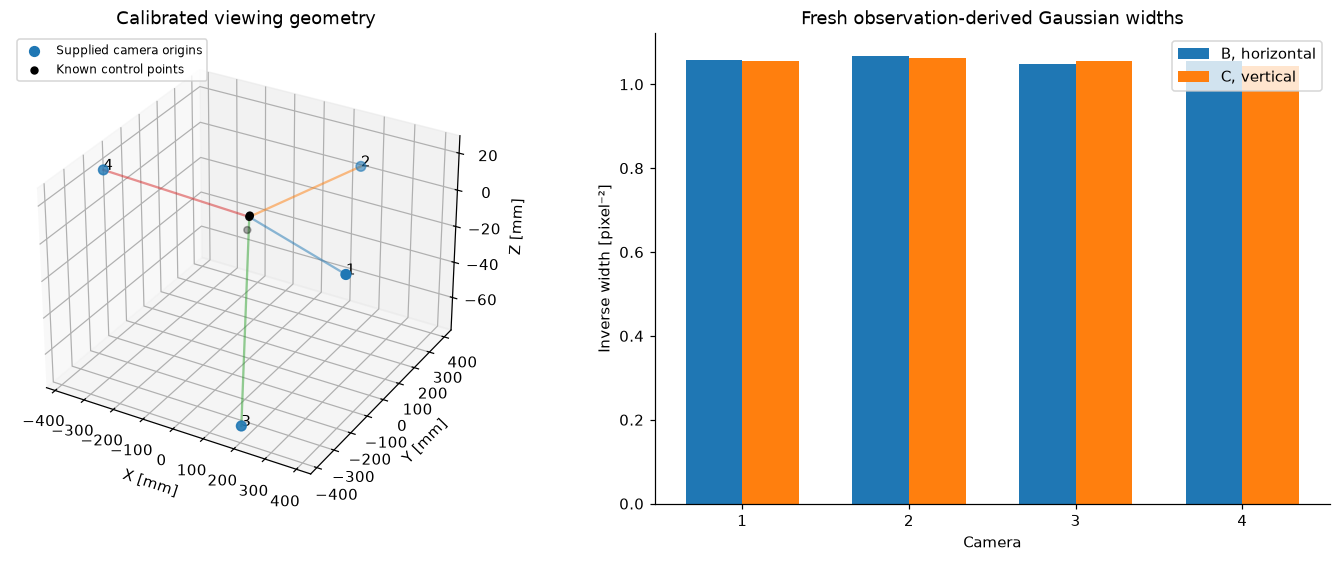

Independent ray error max[mm]: 8.339592596869988e-12


In [3]:
otf=np.array([estimate_otf(data['observations'][0,:5,c])for c in range(4)])
known=np.array([[0.,0.,0.],[3.,-2.,1.],[-10.,6.,-8.]])
ray_errors=[]
for camera in cal:
    ray=rays(project(known,camera),camera);difference=known-ray[:,:3];perpendicular=difference-(difference*ray[:,3:]).sum(axis=1)[:,None]*ray[:,3:];ray_errors.append(np.linalg.norm(perpendicular,axis=1))
fig=plt.figure(figsize=(13,5),layout='constrained');ax=fig.add_subplot(121,projection='3d')
origins=data['camera_centres'][0];ax.scatter(*origins.T,s=40,label='Supplied camera origins');ax.scatter(*known.T,color='black',label='Known control points')
for c,origin in enumerate(origins):ax.plot(*np.array([origin,known[0]]).T,alpha=.5);ax.text(*origin,str(c+1))
ax.set(xlabel='X [mm]',ylabel='Y [mm]',zlabel='Z [mm]',title='Calibrated viewing geometry');ax.legend(loc='upper left',fontsize=8)
ax=fig.add_subplot(122);x=np.arange(4);ax.bar(x-.17,otf[:,1],.34,label='B, horizontal');ax.bar(x+.17,otf[:,2],.34,label='C, vertical');ax.set(xticks=x,xticklabels=np.arange(1,5),xlabel='Camera',ylabel='Inverse width [pixel⁻²]',title='Fresh observation-derived Gaussian widths');ax.legend()
export(fig,2,'Geometry and freshly estimated optical transfer',camera_origins_mm=origins,known_points_mm=known,ray_errors_mm=np.array(ray_errors),fresh_otf=otf)
print('Independent ray error max[mm]:',np.max(ray_errors))

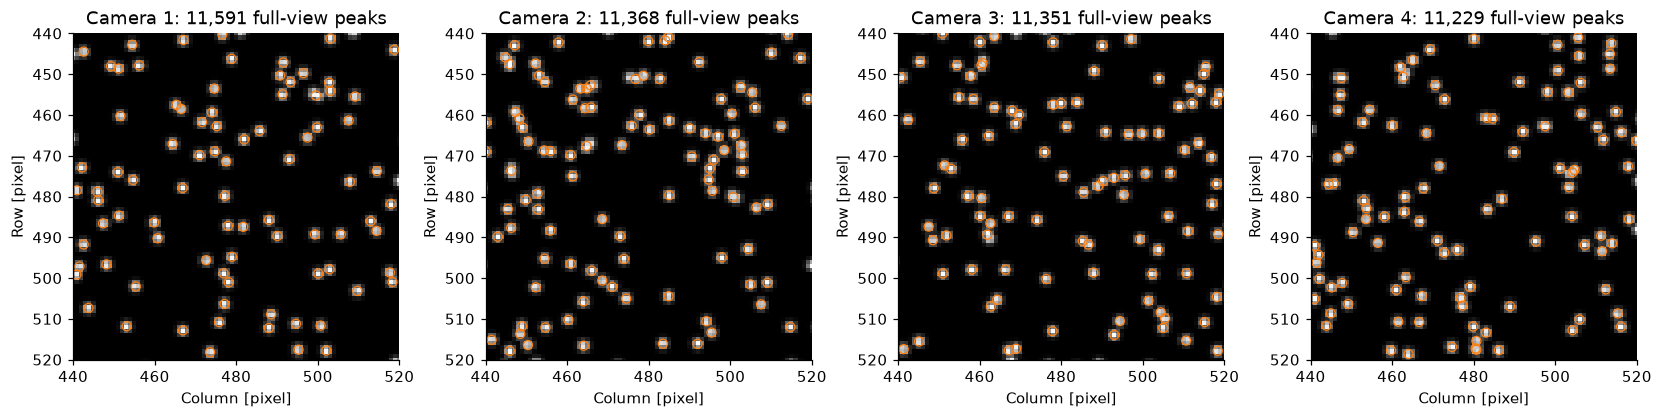

In [4]:
points=[detect(data['observations'][0,0,c])for c in range(4)]
fig,axes=plt.subplots(1,4,figsize=(15,4),layout='constrained')
for c,ax in enumerate(axes):
    ax.imshow(data['observations'][0,0,c],cmap='gray',vmin=0,vmax=124);p=points[c];ix=(p[:,0]>=440)&(p[:,0]<520)&(p[:,1]>=440)&(p[:,1]<520);ax.scatter(p[ix,0],p[ix,1],s=35,facecolors='none',edgecolors='tab:orange',linewidths=.8);ax.set(xlim=(440,520),ylim=(520,440),xlabel='Column [pixel]',ylabel='Row [pixel]',title=f'Camera {c+1}: {len(p):,} full-view peaks')
export(fig,3,'Fresh subpixel detections, display-only detail',**{f'camera_{c}_centres_px':p for c,p in enumerate(points)})

## 4. Method: exclusive correspondences, refinement and trajectory prediction

The current author implementation uses mean percentile preference among competing triangulations, enforcing exclusive two-dimensional peak ownership. This differs from the2020 paper's integer preference count. The following comparison actively computes the complete first-pass candidate cloud, the selected cloud and its refined cloud on frame0. It is a **first-pass mechanism comparison**, not an unexecuted100frame alternative method.

Coordinate refinement minimizes mean active-camera pixel MSE on fixed augmented patches. Four shake widths halve from0.01mm; every coordinate evaluates actual candidate costs. A source defect allowed stale coordinates in the reused trial point. The qualified method resets its full centre at each axis entry; unchanged original results are preserved separately. A known-particle descent control tests physical improvement independently of parity.

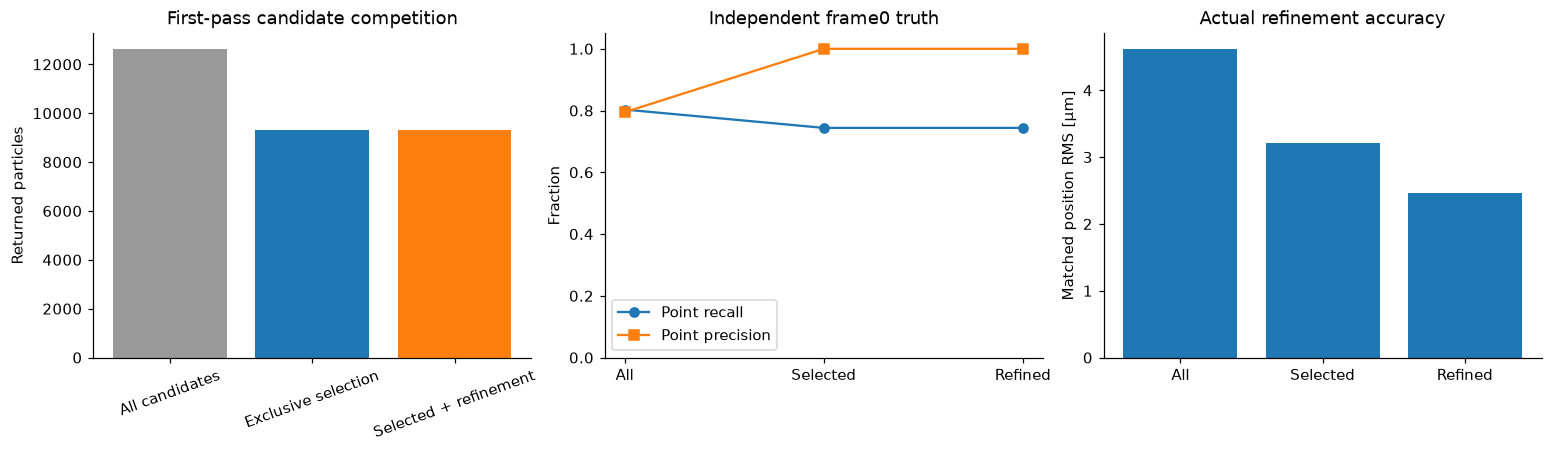

In [5]:
candidates,selected,selected_positions=stereo_diagnostics(points,cal)
all_positions=triangulate_candidates(points,cal,candidates[:,:4]);refined,scores,flags=refine(selected_positions,data['observations'][0,0],cal,otf)
mechanism=np.array([point_case(x)for x in [all_positions,selected_positions,refined[flags==0]]]);labels=['All candidates','Exclusive selection','Selected + refinement']
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained');x=np.arange(3)
axes[0].bar(x,[len(all_positions),len(selected_positions),np.sum(flags==0)],color=['.6','tab:blue','tab:orange']);axes[0].set(ylabel='Returned particles',title='First-pass candidate competition',xticks=x,xticklabels=labels);axes[0].tick_params(axis='x',rotation=20)
axes[1].plot(x,mechanism[:,0],'o-',label='Point recall');axes[1].plot(x,mechanism[:,1],'s-',label='Point precision');axes[1].set(ylim=(0,1.05),ylabel='Fraction',title='Independent frame0 truth',xticks=x,xticklabels=['All','Selected','Refined']);axes[1].legend()
axes[2].bar(x,mechanism[:,2]*1000);axes[2].set(ylabel='Matched position RMS [µm]',title='Actual refinement accuracy',xticks=x,xticklabels=['All','Selected','Refined'])
export(fig,4,'Actual first-pass pruning and refinement comparison',candidate_counts=np.array([len(all_positions),len(selected_positions),np.sum(flags==0)]),truth_metrics=mechanism,all_candidate_positions_mm=all_positions,selected_positions_mm=selected_positions,refined_positions_mm=refined,score=scores,flags=flags)

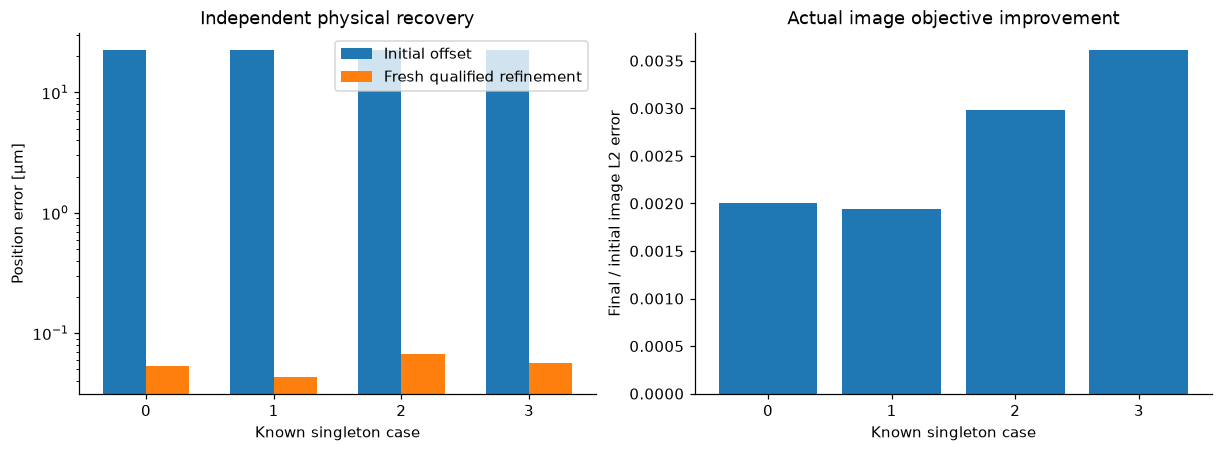

In [6]:
controls=np.array([[0.,0.,0.],[-.73,.42,.61],[6.,-3.,12.],[-10.,6.,-8.]])
initial_error=[];final_error=[];cost_ratio=[]
for control in controls:
    images=known_particle_images(cal,control);initial=control+np.array([.017,-.012,.009]);r,s,f=refine(initial[None],images,cal,np.tile([100.,1.2,1.4],(4,1)));initial_error.append(np.linalg.norm(initial-control));final_error.append(np.linalg.norm(r[0]-control));cost_ratio.append(np.linalg.norm(known_particle_images(cal,r[0])-images)/np.linalg.norm(known_particle_images(cal,initial)-images))
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained');x=np.arange(4);axes[0].bar(x-.17,np.array(initial_error)*1000,.34,label='Initial offset');axes[0].bar(x+.17,np.array(final_error)*1000,.34,label='Fresh qualified refinement');axes[0].set(yscale='log',xlabel='Known singleton case',ylabel='Position error [µm]',title='Independent physical recovery');axes[0].legend()
axes[1].bar(x,cost_ratio);axes[1].set(xlabel='Known singleton case',ylabel='Final / initial image L2 error',title='Actual image objective improvement')
axes[0].set_xticks(x);axes[1].set_xticks(x)
export(fig,5,'Known-particle physical controls',controls_mm=controls,initial_error_mm=np.array(initial_error),final_error_mm=np.array(final_error),image_error_ratio=np.array(cost_ratio))

Initial trajectories use a51³node particle-space displacement field. At each node, local pair displacements form a Gaussian-smoothed histogram; sub-bin log-Gaussian peaks and spatial smoothing provide initialization. Established tracks use adaptive LMS prediction from their last at most six positions, image-domain refinement, residual IPR and conflict-resolved association. Linear last-point consistency prunes erratic tracks. Full details, units, exact stopping and boundary arithmetic are in both plans.

**Active complete reconstruction follows.** The next cell computes every frame anew with owned numerical C++/STL mathematics and public observations. No upstream package or hidden reconstruction is imported.

In [7]:
import subprocess,gc
# Execute the standard CLI as the notebook's active complete reconstruction.
# Release the parent observation buffer before the child loads it, keeping the
# full native acquisition and the required system memory reserve.
del data;gc.collect()
diagnostic_path=FIGURE_DIR.parent/'notebook_fresh_diagnostics.npz'
command=[sys.executable,'-m','src.main','--diagnostics',str(diagnostic_path)]
start=time.perf_counter();process=subprocess.run(command,cwd=ROOT,capture_output=True,text=True,errors='replace');assert process.returncode==0,process.stderr
print(process.stdout[-1800:]);print('Standard CLI native exit:',process.returncode,'wall seconds:',time.perf_counter()-start)
data=load_data(ROOT/'data/raw_data.npz');out=ROOT/'output/reconstruction.npz'
with np.load(out,allow_pickle=False)as z:fresh={k:z[k]for k in z.files}
with np.load(diagnostic_path,allow_pickle=False)as z:diagnostics={k:z[k]for k in z.files}
report=judge.evaluate(out);assert report['passed'],report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
pred=(fresh['positions'][0],fresh['frame_index'][0],fresh['track_id'][0]);metrics,detail=judge.measure(pred,truth,return_details=True)
upstream={}
for label,file in [('Unchanged original','unchanged_upstream_tracks.npz'),('Qualified upstream','qualified_upstream_tracks.npz')]:
    rows=np.load(ROOT/'notebooks/reference_outputs'/file)['rows'];tracks=(rows[:,2:],rows[:,1].astype(np.int16),rows[:,0].astype(np.int32));m,d=judge.measure(tracks,truth,return_details=True);upstream[label]={'tracks':tracks,'metrics':m,'detail':d}
print('Fresh full100frame runtime[s]:',diagnostics['runtime_seconds']);print(json.dumps(report,indent=2))
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_cleaned_measurements.npz',otf=diagnostics['otf'],statistics=diagnostics['statistics'],runtime_seconds=np.array(diagnostics['runtime_seconds']),metric_values=np.array(list(metrics.values())))

 frame 51 long=11953 short=96
local frame 52 long=11954 short=96
local frame 53 long=11953 short=106
local frame 54 long=11968 short=97
local frame 55 long=11976 short=91
local frame 56 long=11980 short=91
local frame 57 long=11976 short=100
local frame 58 long=11979 short=97
local frame 59 long=11994 short=90
local frame 60 long=11995 short=82
local frame 61 long=11997 short=89
local frame 62 long=11998 short=87
local frame 63 long=11995 short=99
local frame 64 long=12003 short=99
local frame 65 long=12006 short=100
local frame 66 long=12012 short=96
local frame 67 long=12015 short=96
local frame 68 long=12020 short=100
local frame 69 long=12033 short=93
local frame 70 long=12043 short=88
local frame 71 long=12052 short=78
local frame 72 long=12047 short=87
local frame 73 long=12043 short=98
local frame 74 long=12043 short=96
local frame 75 long=12043 short=104
local frame 76 long=12061 short=89
local frame 77 long=12072 short=88
local frame 78 long=12088 short=78
local frame 79 long=

## 5. Results: spatial accuracy and temporal completeness

The independent manifest retains every author point in every frame. No output-conditioned visibility or accuracy mask is used. Point error is conditional on unique matches, so missing/extra points and temporal edges are scored separately. Arbitrary numerical track labels are compared through their physical connections, not label equality with truth.

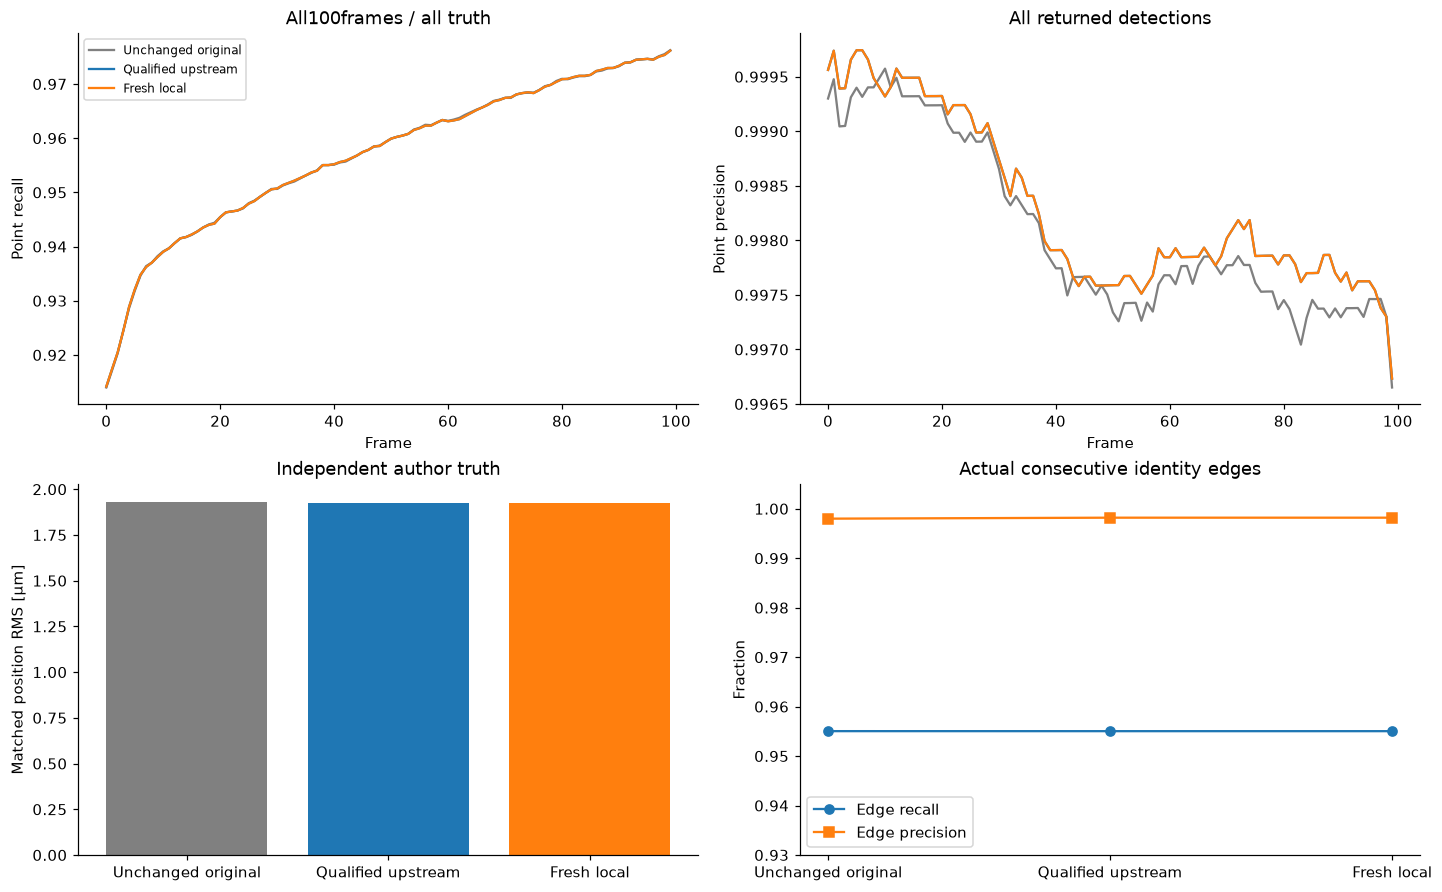

In [8]:
fig,axes=plt.subplots(2,2,figsize=(13,8),layout='constrained');colors=['.5','tab:blue','tab:orange']
groups=[*upstream.items(),('Fresh local',{'metrics':metrics,'detail':detail})]
for color,(label,group)in zip(colors,groups):
    f=group['detail']['frame_metrics'];axes[0,0].plot(f[:,0],f[:,3],color=color,label=label);axes[0,1].plot(f[:,0],f[:,4],color=color,label=label)
axes[0,0].set(ylabel='Point recall',xlabel='Frame',title='All100frames / all truth');axes[0,1].set(ylabel='Point precision',xlabel='Frame',title='All returned detections');axes[0,0].legend(fontsize=8)
x=np.arange(3);axes[1,0].bar(x,[g['metrics']['position_rms_mm']*1000 for _,g in groups],color=colors);axes[1,0].set(xticks=x,xticklabels=[l for l,_ in groups],ylabel='Matched position RMS [µm]',title='Independent author truth')
axes[1,1].plot(x,[g['metrics']['edge_recall']for _,g in groups],'o-',label='Edge recall');axes[1,1].plot(x,[g['metrics']['edge_precision']for _,g in groups],'s-',label='Edge precision');axes[1,1].set(xticks=x,xticklabels=[l for l,_ in groups],ylim=(.93,1.005),ylabel='Fraction',title='Actual consecutive identity edges');axes[1,1].legend()
export(fig,6,'Unchanged original, qualified upstream and fresh full results',fresh_frame_metrics=detail['frame_metrics'],original_frame_metrics=upstream['Unchanged original']['detail']['frame_metrics'],qualified_frame_metrics=upstream['Qualified upstream']['detail']['frame_metrics'],all_method_metrics=np.array([list(g['metrics'].values())for _,g in groups]))

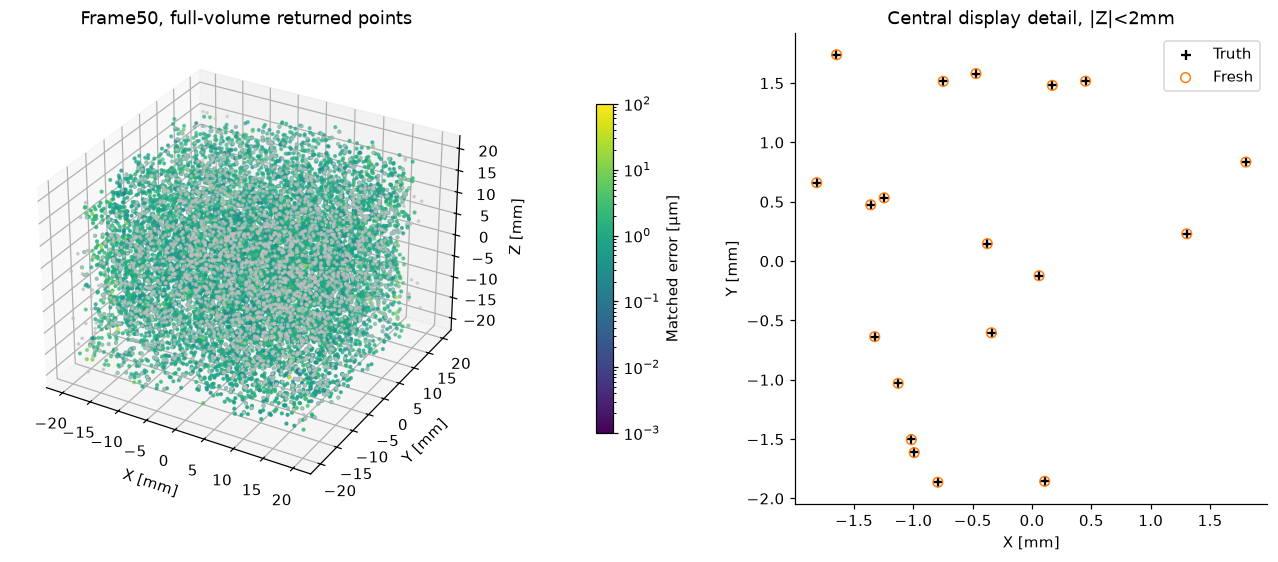

In [9]:
frame=50;ix=np.flatnonzero(pred[1]==frame);matched=detail['matched_identity'][ix]>=0;p=pred[0][ix];errors=detail['distance_mm'][ix];q=truth[0][truth[1]==frame]
fig=plt.figure(figsize=(14,5),layout='constrained');ax=fig.add_subplot(121,projection='3d');ax.scatter(*q[::4].T,s=2,c='.75',label='Truth, display every4th');im=ax.scatter(*p[matched].T,s=3,c=errors[matched]*1000,cmap='viridis',norm=LogNorm(vmin=.001,vmax=100));ax.set(xlabel='X [mm]',ylabel='Y [mm]',zlabel='Z [mm]',title='Frame50, full-volume returned points');fig.colorbar(im,ax=ax,shrink=.7,pad=.15,label='Matched error [µm]')
ax=fig.add_subplot(122);zoom=(np.abs(p[:,0])<2)&(np.abs(p[:,1])<2)&(np.abs(p[:,2])<2);qt=np.all(np.abs(q)<2,axis=1);ax.scatter(q[qt,0],q[qt,1],marker='+',s=50,c='black',label='Truth');ax.scatter(p[zoom,0],p[zoom,1],facecolors='none',edgecolors='tab:orange',s=40,label='Fresh');ax.set(xlabel='X [mm]',ylabel='Y [mm]',title='Central display detail, |Z|<2mm');ax.legend();ax.set_aspect('equal')
export(fig,7,'Full-volume spatial error and local detail',frame=np.array(frame),fresh_positions_mm=p,truth_positions_mm=q,matched=matched,error_matched_mm=errors[matched])

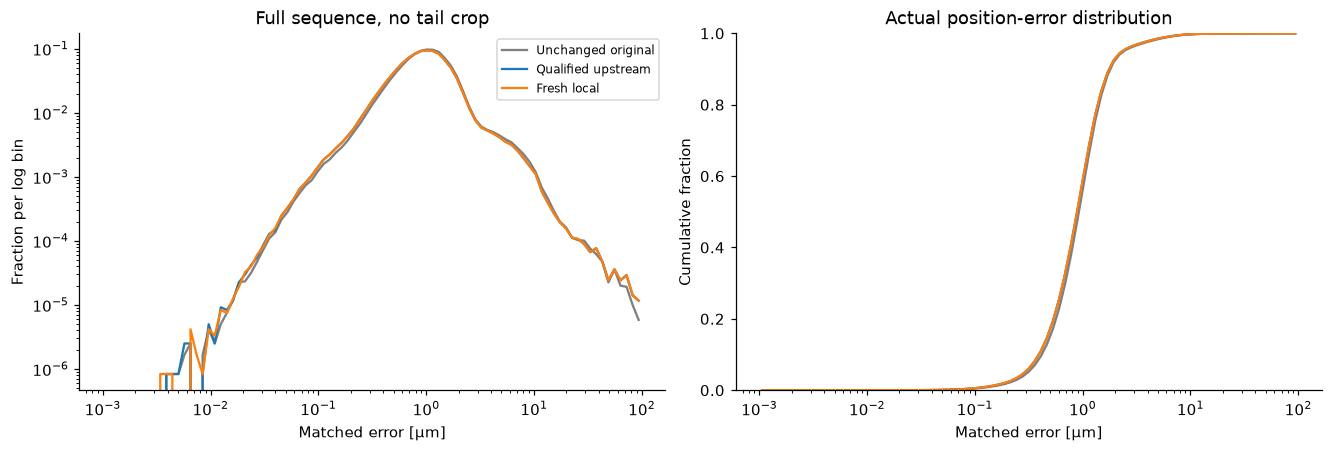

In [10]:
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained');numeric={}
for color,(label,g)in zip(colors,groups):
    error=g['detail']['distance_mm'];error=error[np.isfinite(error)];hist,bins=np.histogram(error*1000,bins=np.geomspace(.001,100,90));centres=np.sqrt(bins[:-1]*bins[1:]);axes[0].plot(centres,hist/len(error),label=label,color=color);axes[1].plot(centres,np.cumsum(hist)/len(error),label=label,color=color);numeric[label.replace(' ','_')+'_histogram']=hist
axes[0].set(xscale='log',yscale='log',xlabel='Matched error [µm]',ylabel='Fraction per log bin',title='Full sequence, no tail crop');axes[1].set(xscale='log',xlabel='Matched error [µm]',ylabel='Cumulative fraction',ylim=(0,1),title='Actual position-error distribution');axes[0].legend(fontsize=8)
export(fig,8,'Full-sequence position-error distributions',bins_um=bins,**numeric)

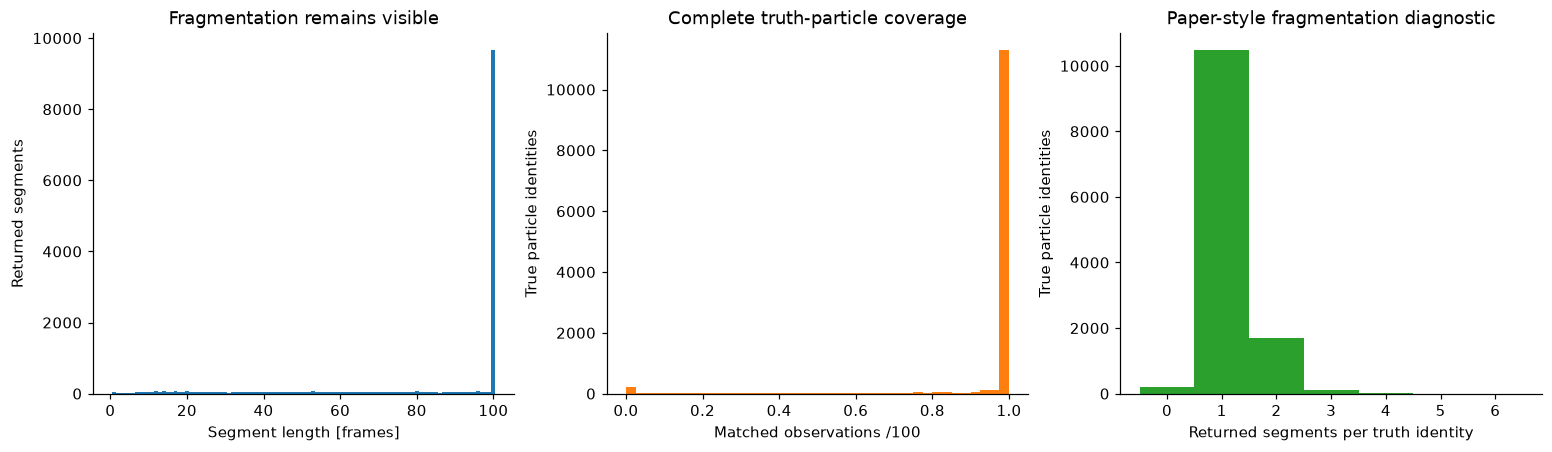

In [11]:
labels,count=np.unique(pred[2],return_counts=True);matched=detail['matched_identity'];coverage=np.bincount(matched[matched>=0],minlength=12500)/100
pairs=np.unique(np.c_[matched[matched>=0],pred[2][matched>=0]],axis=0);fragmentation=np.bincount(pairs[:,0],minlength=12500)
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained');axes[0].hist(count,bins=np.arange(.5,101.5,1),color='tab:blue');axes[0].set(xlabel='Segment length [frames]',ylabel='Returned segments',title='Fragmentation remains visible');axes[1].hist(coverage,bins=np.linspace(0,1,41),color='tab:orange');axes[1].set(xlabel='Matched observations /100',ylabel='True particle identities',title='Complete truth-particle coverage');axes[2].hist(fragmentation,bins=np.arange(-.5,fragmentation.max()+1.5),color='tab:green');axes[2].set(xlabel='Returned segments per truth identity',ylabel='True particle identities',title='Paper-style fragmentation diagnostic')
export(fig,9,'Coverage and fragmentation without singleton loopholes',segment_lengths=count,truth_coverage=coverage,truth_fragmentation=fragmentation)

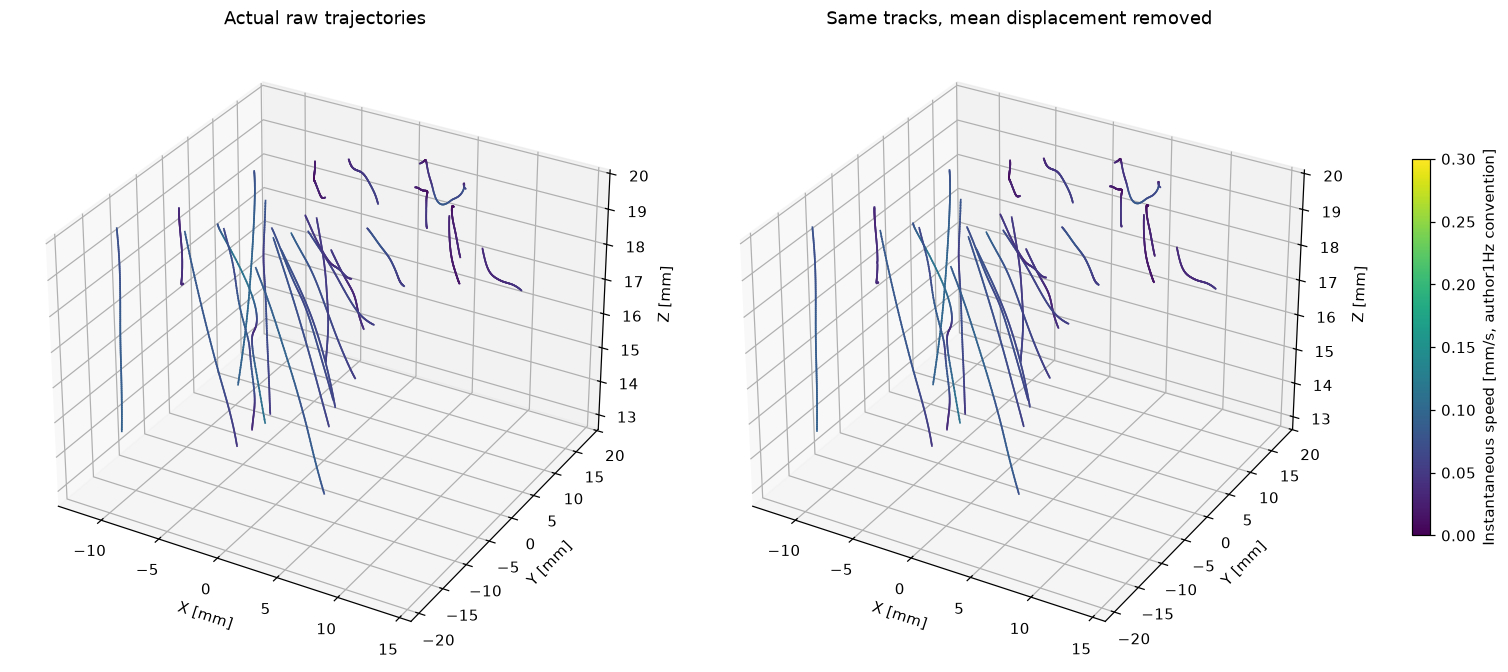

In [12]:
a,b,velocity=segment_velocity(*pred);speed=np.linalg.norm(velocity,axis=1);chosen=labels[count==100][:24]
fig=plt.figure(figsize=(14,6),layout='constrained');axes=[fig.add_subplot(121,projection='3d'),fig.add_subplot(122,projection='3d')]
mean_velocity=np.mean(velocity,axis=0)
for track in chosen:
    ix=np.flatnonzero(pred[2]==track);ix=ix[np.argsort(pred[1][ix])];p=pred[0][ix];t=pred[1][ix];v=np.linalg.norm(np.diff(p,axis=0),axis=1)
    for ax,remove in zip(axes,[False,True]):
        positions=p-(t-t[0])[:,None]*mean_velocity if remove else p
        for j in range(len(p)-1):ax.plot(*positions[j:j+2].T,c=plt.cm.viridis(np.clip(v[j]/.3,0,1)),lw=1.1)
axes[0].set(title='Actual raw trajectories',xlabel='X [mm]',ylabel='Y [mm]',zlabel='Z [mm]');axes[1].set(title='Same tracks, mean displacement removed',xlabel='X [mm]',ylabel='Y [mm]',zlabel='Z [mm]')
scalar=plt.cm.ScalarMappable(norm=plt.Normalize(0,.3),cmap='viridis');fig.colorbar(scalar,ax=axes,shrink=.6,label='Instantaneous speed [mm/s, author1Hz convention]')
export(fig,10,'Velocity-colored trajectories and mean-flow subtraction',chosen_track_ids=chosen,mean_velocity_mm_s=mean_velocity,speed_mm_s=speed)

The paper compares raw and smoothed tracks and warns that a smoothed reconstruction is not independent truth. Here genuine simulated truth permits a direct comparison. Gaussian smoothing below is a labelled diagnostic, applied per returned segment with nearest endpoint continuation. It never changes the submitted reconstruction or its acceptance criteria.

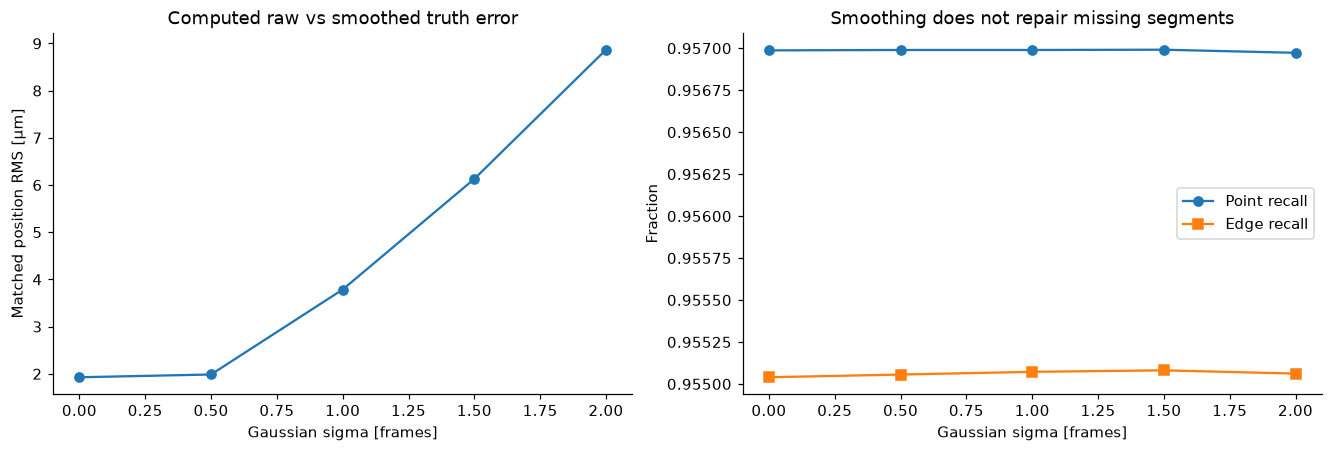

In [13]:
sigmas=np.array([0,.5,1.,1.5,2.]);smoothing_metrics=[]
for sigma in sigmas:
    smoothed=pred[0] if sigma==0 else gaussian_smooth_tracks(*pred,sigma=sigma);m=judge.measure((smoothed,pred[1],pred[2]),truth);smoothing_metrics.append(list(m.values()))
smoothing_metrics=np.asarray(smoothing_metrics);fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained');axes[0].plot(sigmas,smoothing_metrics[:,2]*1000,'o-');axes[0].set(xlabel='Gaussian sigma [frames]',ylabel='Matched position RMS [µm]',title='Computed raw vs smoothed truth error');axes[1].plot(sigmas,smoothing_metrics[:,0],'o-',label='Point recall');axes[1].plot(sigmas,smoothing_metrics[:,3],'s-',label='Edge recall');axes[1].set(xlabel='Gaussian sigma [frames]',ylabel='Fraction',title='Smoothing does not repair missing segments');axes[1].legend()
export(fig,11,'Actual smoothing sensitivity, full100frames',sigma_frames=sigmas,metrics=smoothing_metrics)

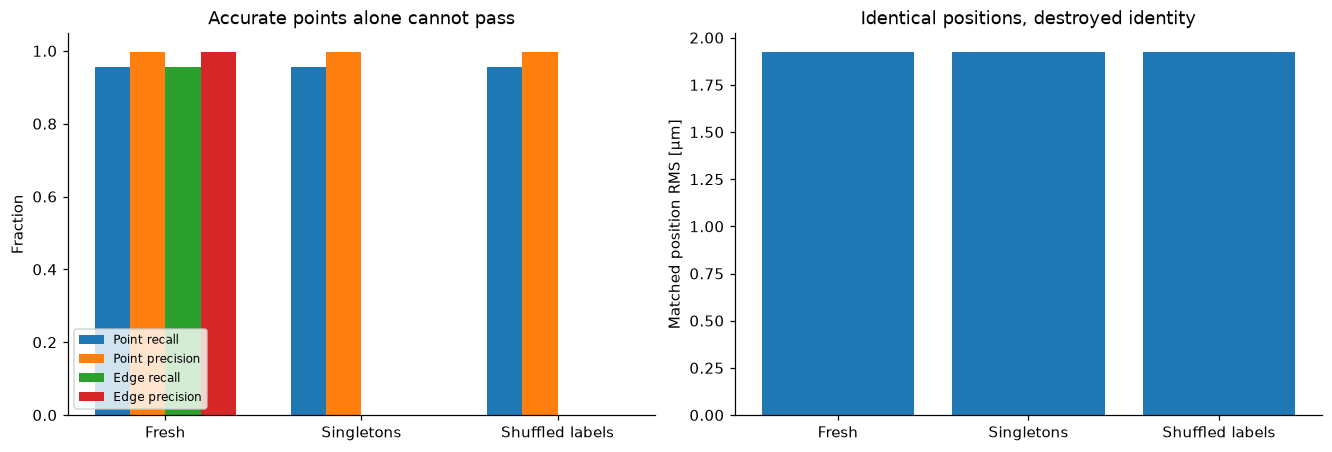

In [14]:
poor={}
for label,ids in [('Singletons',np.arange(len(pred[0]),dtype=np.int32)),('Shuffled labels',np.random.default_rng(20261022).permutation(pred[2]))]:poor[label]=judge.measure((pred[0],pred[1],ids),truth)
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained');names=['Fresh',*poor];values=np.array([list(metrics.values()),*[list(v.values())for v in poor.values()]]);x=np.arange(3)
for j,(k,label)in enumerate([(0,'Point recall'),(1,'Point precision'),(3,'Edge recall'),(4,'Edge precision')]):axes[0].bar(x+(j-1.5)*.18,values[:,k],.18,label=label)
axes[0].set(xticks=x,xticklabels=names,ylabel='Fraction',title='Accurate points alone cannot pass');axes[0].legend(fontsize=8,loc='lower left');axes[1].bar(x,values[:,2]*1000);axes[1].set(xticks=x,xticklabels=names,ylabel='Matched position RMS [µm]',title='Identical positions, destroyed identity')
export(fig,12,'Meaningful identity-null controls',all_metrics=values)

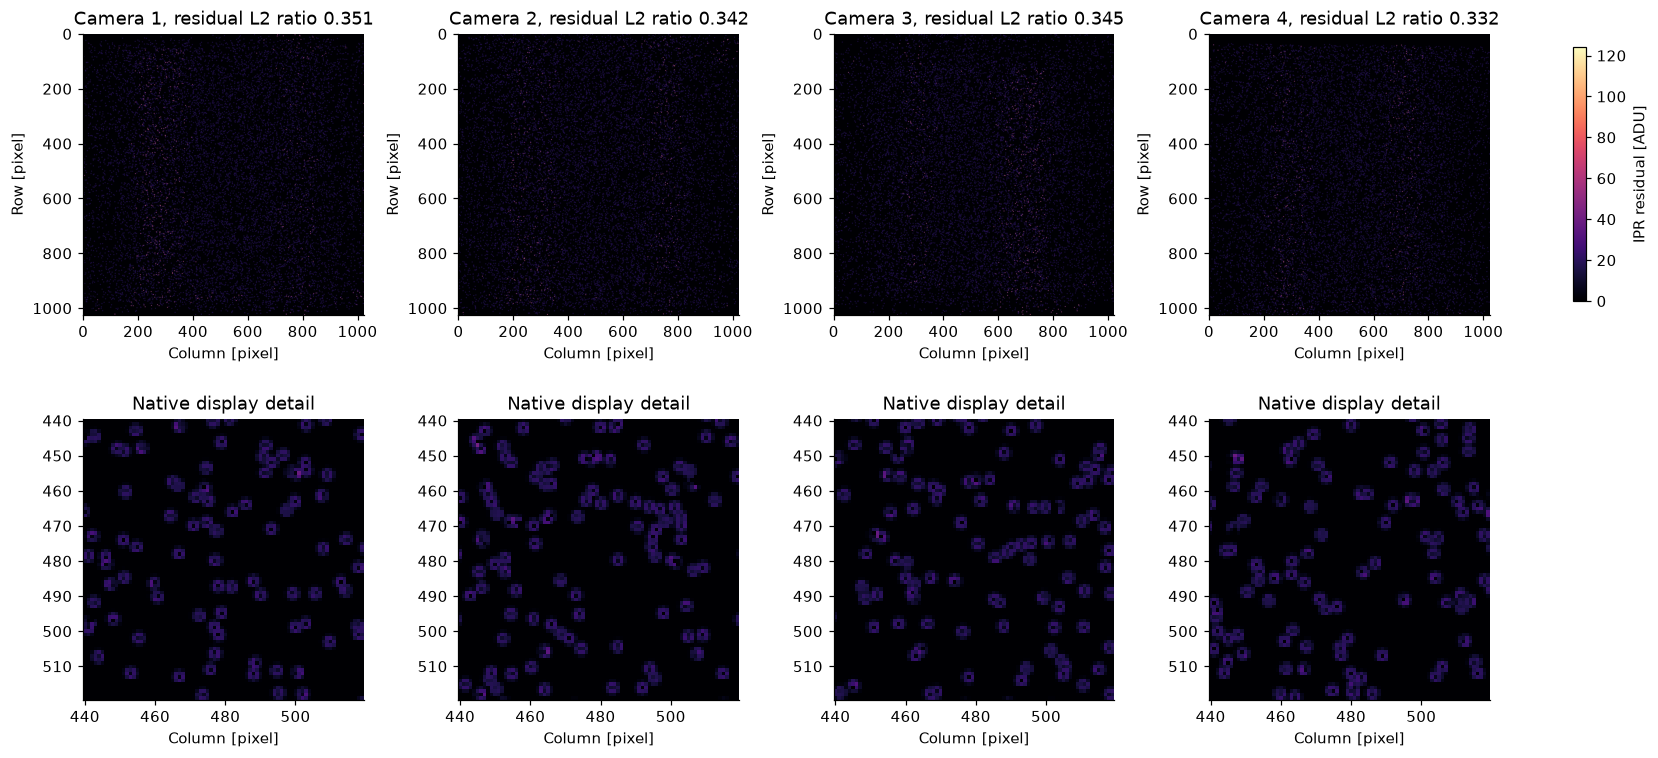

In [15]:
first_ipr=reconstruct_frame(data['observations'][0,0],cal,otf);res=residual(first_ipr,data['observations'][0,0],cal,otf)
fig,axes=plt.subplots(2,4,figsize=(15,7),layout='constrained');ratios=[]
for c in range(4):
    original=data['observations'][0,0,c].astype(float);ratios.append(np.linalg.norm(res[c])/np.linalg.norm(original));im=axes[0,c].imshow(res[c],cmap='magma',vmin=0,vmax=124);axes[0,c].set_title(f'Camera {c+1}, residual L2 ratio {ratios[-1]:.3f}');axes[0,c].set_xlabel('Column [pixel]');axes[0,c].set_ylabel('Row [pixel]');axes[1,c].imshow(res[c,440:520,440:520],cmap='magma',vmin=0,vmax=124,extent=[439.5,519.5,519.5,439.5]);axes[1,c].set_title('Native display detail');axes[1,c].set_xlabel('Column [pixel]')
fig.colorbar(im,ax=axes[0,:],label='IPR residual [ADU]',shrink=.7)
export(fig,13,'Actual minimum-fusion IPR residuals',residual_images=res,relative_l2=np.array(ratios),fresh_ipr_positions_mm=first_ipr)

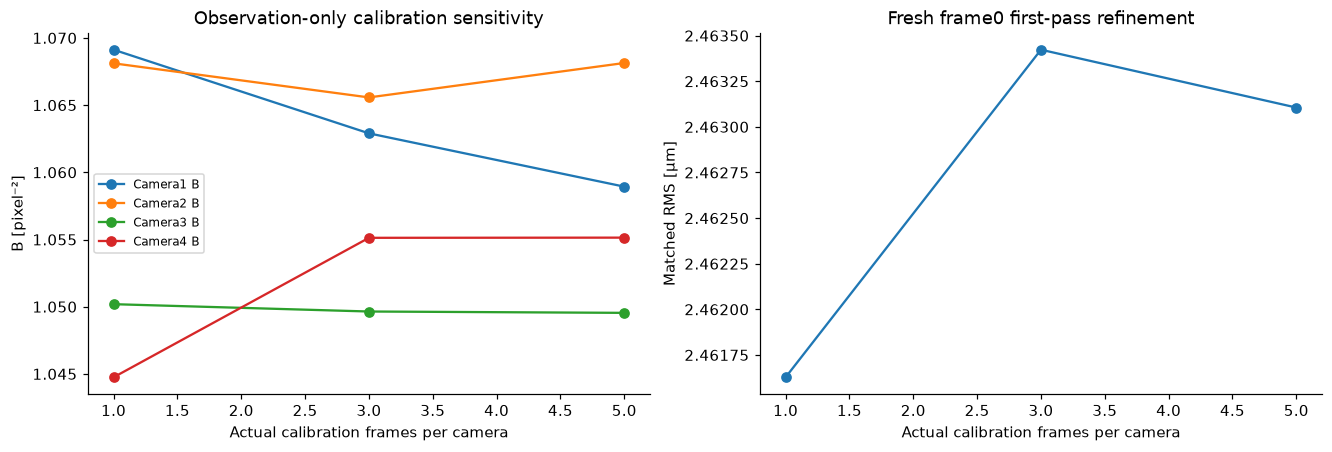

In [16]:
calibration_lengths=np.array([1,3,5]);calibration_metrics=[];widths=[]
for length in calibration_lengths:
    fitted=np.array([estimate_otf(data['observations'][0,:length,c])for c in range(4)]);q,s,f=refine(selected_positions,data['observations'][0,0],cal,fitted);widths.append(fitted);calibration_metrics.append(point_case(q[f==0]))
calibration_metrics=np.asarray(calibration_metrics);widths=np.asarray(widths);fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for c in range(4):axes[0].plot(calibration_lengths,widths[:,c,1],'o-',label=f'Camera{c+1} B')
axes[0].set(xlabel='Actual calibration frames per camera',ylabel='B [pixel⁻²]',title='Observation-only calibration sensitivity');axes[0].legend(fontsize=8);axes[1].plot(calibration_lengths,calibration_metrics[:,2]*1000,'o-');axes[1].set(xlabel='Actual calibration frames per camera',ylabel='Matched RMS [µm]',title='Fresh frame0 first-pass refinement')
export(fig,14,'Measured calibration-length sensitivity',calibration_lengths=calibration_lengths,otf=widths,truth_metrics=calibration_metrics)

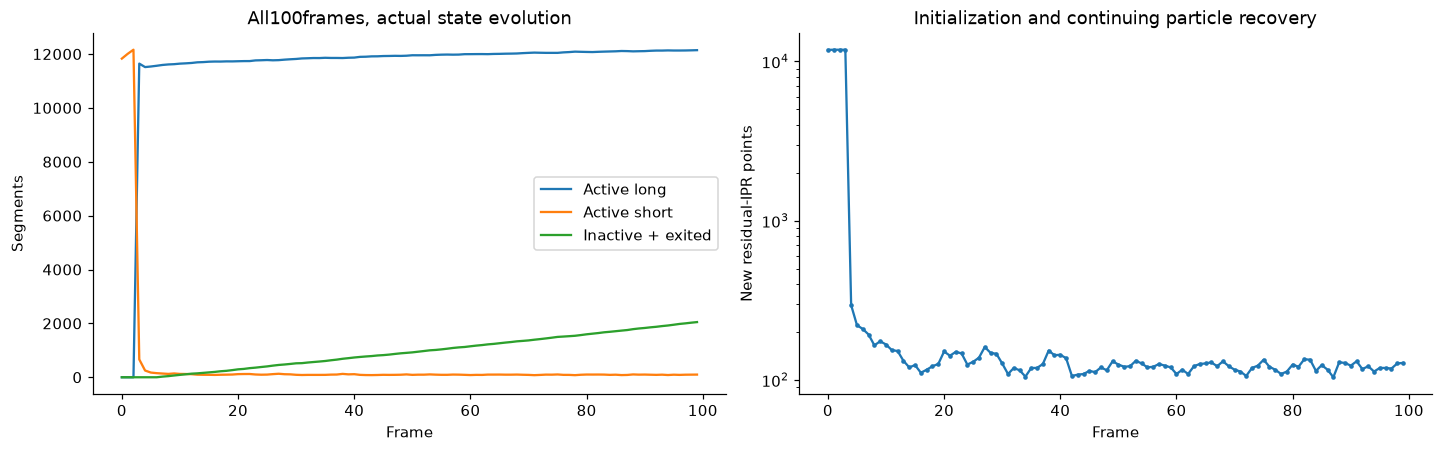

Exported actual figure groups: 15
Final all-quantity Judge: pass


In [17]:
statistics=diagnostics['statistics'];fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained');axes[0].plot(statistics[:,1],label='Active long');axes[0].plot(statistics[:,2],label='Active short');axes[0].plot(statistics[:,3],label='Inactive + exited');axes[0].set(xlabel='Frame',ylabel='Segments',title='All100frames, actual state evolution');axes[0].legend()
axes[1].plot(statistics[:,0],'o-',ms=2);axes[1].set(xlabel='Frame',ylabel='New residual-IPR points',title='Initialization and continuing particle recovery',yscale='log')
export(fig,15,'Complete pipeline state and fresh-particle recovery',statistics=statistics,runtime_seconds=np.array(diagnostics['runtime_seconds']))
(FIGURE_DIR/'figure_index.json').write_text(json.dumps(figure_index,indent=2),encoding='utf8')
print('Exported actual figure groups:',len(figure_index));print('Final all-quantity Judge:',report['status'])

## 6. Conclusion and limits

The fresh explicit local method reconstructs the entire supplied100frame sequence and passes all five previously frozen truth criteria. Spatial coverage, conditional position error and consecutive temporal identity are evaluated together; singleton and shuffled labels demonstrate the necessity of connectivity scoring. The source coordinate-state correction has independent physical descent evidence and is clearly separated from the unchanged original.

This dataset is an existing author simulation, not evidence of real-world camera robustness. The modern code uses different pruning and configuration from the2020 paper, and its min-fusion overlap approximation leaves genuine image residuals. Paper experiments varying particle density, optical depth of field, calibration error and shadow blurring require different acquisitions and are not fabricated here. Their key mechanism comparisons—candidate pruning, raw/smoothed position accuracy, coverage/fragmentation/correctness and velocity-colored trajectories—are retained as actual comparisons on the bound acquisition, with scope stated per figure. External data redistribution terms remain unspecified; the present work is local research/benchmark use.